## csv 파일 읽고 데이터프레임 설정 후 확인


In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic' #폰트설정
plt.rcParams['axes.unicode_minus'] = False


def load_dataset(filename):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding='euc-kr')

In [84]:
df = load_dataset('컨테이너_수송통계')

In [85]:
df.head(3)    #상위 3개 확인

,년도,합계,자성대부두,신선대부두,감만부두,우암부두,감천한진,신감만부두,일반부두,신항1부두,신항2부두,신항3부두,신항4부두,신항5부두,다목적부두등
0,1994,48140,0,0,0,0,0,0,48140,0,0,0,0,0,0
1,1995,59775,0,622,0,0,0,0,59153,0,0,0,0,0,0
2,1996,4809217,1673341,1302513,0,21171,0,0,1812192,0,0,0,0,0,0


## 결측치 확인

In [86]:
df.isnull().sum()

년도        0
합계        0
자성대부두     0
신선대부두     0
감만부두      0
우암부두      0
감천한진      0
신감만부두     0
일반부두      0
신항1부두     0
신항2부두     0
신항3부두     0
신항4부두     0
신항5부두     0
다목적부두등    0
dtype: int64

In [88]:
sin_df = df[['년도', '신항1부두', '신항2부두', '신항3부두', '신항4부두', '신항5부두']] #년도, 신항1~5부두만 표현

sin_df.head()



,년도,신항1부두,신항2부두,신항3부두,신항4부두,신항5부두
0,1994,0,0,0,0,0
1,1995,0,0,0,0,0
2,1996,0,0,0,0,0
3,1997,0,0,0,0,0
4,1998,0,0,0,0,0


### 24년도 신항1~5부두 값 확인


In [89]:

sin_2024 = df.loc[
    df['년도'] == 2024,
    ['년도', '신항1부두', '신항2부두', '신항3부두',
     '신항4부두', '신항5부두']
]

sin_2024


,년도,신항1부두,신항2부두,신항3부두,신항4부두,신항5부두
30,2024,3018315,4957906,3076160,2560274,2422973


### 신항 1~5부두 하역능력 값 추가

In [90]:
capacity_df = pd.DataFrame({
    '부두': ['신항1부두', '신항2부두', '신항3부두',
           '신항4부두', '신항5부두', '신항6부두', '신항7부두'],
    '하역능력': [2090000, 3790000, 2310000,
             1930000, 2440000, 1950000, 1950000]
})

capacity_df

,부두,하역능력
0,신항1부두,2090000
1,신항2부두,3790000
2,신항3부두,2310000
3,신항4부두,1930000
4,신항5부두,2440000
5,신항6부두,1950000
6,신항7부두,1950000


### 신항 처리실적 값 추출

In [91]:
sin_2024 = df.loc[
    df['년도'] == 2024,
    ['신항1부두', '신항2부두', '신항3부두',
     '신항4부두', '신항5부두']
]

sin_2024 = sin_2024.T.reset_index()

sin_2024.columns = ['부두', '처리실적']

sin_2024

,부두,처리실적
0,신항1부두,3018315
1,신항2부두,4957906
2,신항3부두,3076160
3,신항4부두,2560274
4,신항5부두,2422973


### 활용률 구하기

In [92]:
result_df = pd.merge(sin_2024, capacity_df, on='부두')

result_df['활용률(%)'] = (
    result_df['처리실적'] / result_df['하역능력'] * 100
).round(2)

result_df

,부두,처리실적,하역능력,활용률(%)
0,신항1부두,3018315,2090000,144.42
1,신항2부두,4957906,3790000,130.82
2,신항3부두,3076160,2310000,133.17
3,신항4부두,2560274,1930000,132.66
4,신항5부두,2422973,2440000,99.30


### 하역능력 비중 재계산

In [97]:
# 신항 6, 7부두 제외
capacity_df = capacity_df[
    ~capacity_df['부두'].isin(['신항6부두', '신항7부두'])
].copy()

capacity_df['하역능력비중(%)'] = (
    capacity_df['하역능력'] / capacity_df['하역능력'].sum() * 100
).round(2)

capacity_df

,부두,하역능력,하역능력비중(%)
0,신항1부두,2090000,16.64
1,신항2부두,3790000,30.18
2,신항3부두,2310000,18.39
3,신항4부두,1930000,15.37
4,신항5부두,2440000,19.43


In [99]:

from IPython.display import display

#신항 1~5부두 하역능력
capacity_df = pd.DataFrame({
    '부두': ['신항1부두', '신항2부두', '신항3부두',
           '신항4부두', '신항5부두'],
    '하역능력': [2090000, 3790000, 2310000,
             1930000, 2440000]
})

# 2024년 실제 처리실적 추출
sin_2024 = df[df['년도'] == 2024]

# 부두별 실제 처리실적 합계
actual_df = (
    sin_2024[capacity_df['부두'].tolist()]
    .sum()
    .reset_index()
)

actual_df.columns = ['부두', '실제처리실적']

# 하역능력과 실제 처리실적 병합
result_df = pd.merge(capacity_df, actual_df, on='부두')

# 하역능력 비중 계산
result_df['하역능력비중(%)'] = (
        result_df['하역능력'] / result_df['하역능력'].sum() * 100
).round(2)

# 기존 하역능력 활용률 계산
result_df['기존활용률(%)'] = (
        result_df['실제처리실적'] / result_df['하역능력'] * 100
).round(2)

# 잔여 하역능력 계산
result_df['잔여하역능력'] = (
        result_df['하역능력'] - result_df['실제처리실적']
)

# 전체 물동량과 하역능력 합계
total_actual = result_df['실제처리실적'].sum()
total_capacity = result_df['하역능력'].sum()

# 하역능력 비중에 따른 물동량 재배분
result_df['재배분후물동량'] = (
        total_actual * result_df['하역능력'] / total_capacity
)

# 물동량 조정량 계산
result_df['물동량조정량'] = (
        result_df['재배분후물동량'] - result_df['실제처리실적']
)

# 재배분 후 하역능력 활용률
result_df['재배분후활용률(%)'] = (
        result_df['재배분후물동량'] / result_df['하역능력'] * 100
).round(2)

# 원본 데이터 복사
display_df = result_df.copy()

# 1,000 TEU 단위로 표시할 컬럼
cols = [
    '하역능력',
    '실제처리실적',
    '잔여하역능력',
    '재배분후물동량',
    '물동량조정량'
]

# 1,000 TEU 단위로 변환
for col in cols:
    display_df[col] = np.trunc(
        display_df[col] / 1000
    ).astype(int)

# 표 출력
display(
    display_df.style.format({
        **{col: '{:,.0f}' for col in cols},
        '하역능력비중(%)': '{:.2f}',
        '기존활용률(%)': '{:.2f}',
        '재배분후활용률(%)': '{:.2f}'
    })
)

# 표 아래 단위 표시
print('(단위: 1,000 TEU)')

,부두,하역능력,실제처리실적,하역능력비중(%),기존활용률(%),잔여하역능력,재배분후물동량,물동량조정량,재배분후활용률(%)
0,신항1부두,"2,090","3,018",16.64,144.42,-928,"2,668",-349,127.67
1,신항2부두,"3,790","4,957",30.18,130.82,"-1,167","4,838",-119,127.67
2,신항3부두,"2,310","3,076",18.39,133.17,-766,"2,949",-126,127.67
3,신항4부두,"1,930","2,560",15.37,132.66,-630,"2,464",-96,127.67
4,신항5부두,"2,440","2,422",19.43,99.30,17,"3,115",692,127.67


(단위: 1,000 TEU)


## 2024년 부산신항 물동량 재배분 전후 비교

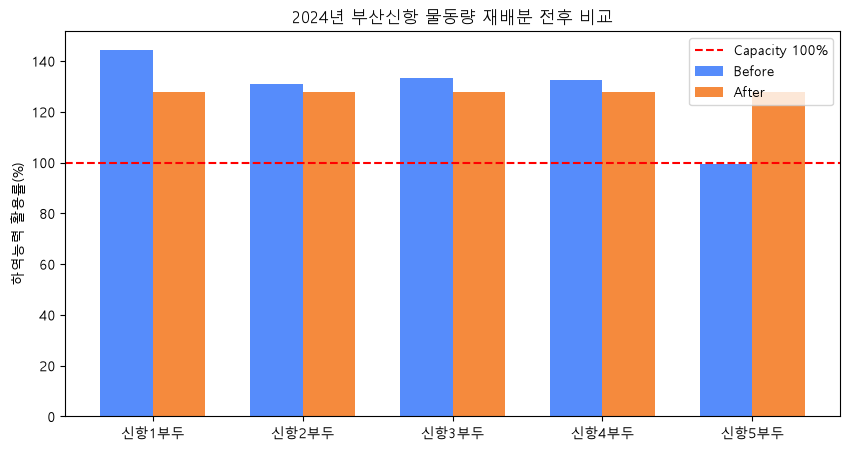

In [95]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(result_df))
width = 0.35

ax.bar(
    [i - width/2 for i in x],
    result_df['기존활용률(%)'],
    width=width,
    label='Before'
)

ax.bar(
    [i + width/2 for i in x],
    result_df['재배분후활용률(%)'],
    width=width,
    label='After'
)

ax.axhline(100, color='red', linestyle='--', label='Capacity 100%')

ax.set_xticks(list(x))
ax.set_xticklabels(result_df['부두'])
ax.set_ylabel('하역능력 활용률(%)')
ax.set_title('2024년 부산신항 물동량 재배분 전후 비교')
ax.legend()

plt.show()